# SWYNEX Internship — Task 3
## Modeling and Evaluation

### Objective
Build, train, and evaluate a baseline machine learning model for predicting student final scores.

### Model Used
- Linear Regression

### Evaluation Metrics
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [11]:
df = pd.read_csv("cleaned_student_data.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (25, 10)


,student_id,name,age,gender,attendance_pct,study_hours_per_week,previous_score,final_score,department,city
0,S001,Rahul Sharma,20,Male,85.0,12.0,72.0,78.0,CSE,Bhopal
1,S002,Priya Verma,21,Female,90.0,15.0,81.0,88.0,CSE,Indore
2,S003,Aman Khan,19,Male,75.0,8.0,61.0,65.0,ECE,Bhopal
3,S004,Sneha Patel,20,Female,86.5,14.0,77.0,82.0,CSE,Indore
4,S005,Arjun Singh,22,Male,88.0,10.0,69.0,74.0,ME,Gwalior


In [12]:
print("Column Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Column Names:
['student_id', 'name', 'age', 'gender', 'attendance_pct', 'study_hours_per_week', 'previous_score', 'final_score', 'department', 'city']

Missing Values:
student_id              0
name                    0
age                     0
gender                  0
attendance_pct          0
study_hours_per_week    0
previous_score          0
final_score             0
department              0
city                    0
dtype: int64

Data Types:
student_id               object
name                     object
age                       int64
gender                   object
attendance_pct          float64
study_hours_per_week    float64
previous_score          float64
final_score             float64
department               object
city                     object
dtype: object


## Feature Selection

The target variable is **final_score**, as the objective is to predict students' final scores.

The selected features are:

- attendance_pct
- study_hours_per_week
- previous_score

These features were selected based on their relevance to student academic performance.

In [13]:
X = df[["attendance_pct", "study_hours_per_week", "previous_score"]]
y = df["final_score"]

print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,attendance_pct,study_hours_per_week,previous_score
0,85.0,12.0,72.0
1,90.0,15.0,81.0
2,75.0,8.0,61.0
3,86.5,14.0,77.0
4,88.0,10.0,69.0



Target:


,final_score
0,78.0
1,88.0
2,65.0
3,82.0
4,74.0


## Train-Test Split

The dataset is divided into training and testing sets.

- 80% of the data is used for training.
- 20% is used for testing.
- `random_state=42` ensures reproducible results.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 20
Testing samples: 5


## Model Training

A Linear Regression model is used as the baseline regression model.

Linear Regression attempts to model the relationship between the selected input features and the Final Score.

In [15]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [16]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Final Score": y_test.values,
    "Predicted Final Score": y_pred
})

results

,Actual Final Score,Predicted Final Score
0,76.0,74.820368
1,77.0,78.056909
2,78.0,78.443621
3,68.0,67.550936
4,96.0,100.274844


## Model Evaluation

The model is evaluated using four standard regression metrics:

- **MAE:** Average absolute prediction error.
- **MSE:** Average squared prediction error.
- **RMSE:** Square root of MSE, expressed in the same unit as the target.
- **R² Score:** Measures how much variation in the target is explained by the model.

In [17]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.2f}")

Model Evaluation Results
-------------------------
MAE  : 1.48
MSE  : 4.24
RMSE : 2.06
R²   : 0.95


## Actual vs Predicted Final Scores

The following plot compares the actual Final Scores with the scores predicted by the Linear Regression model.

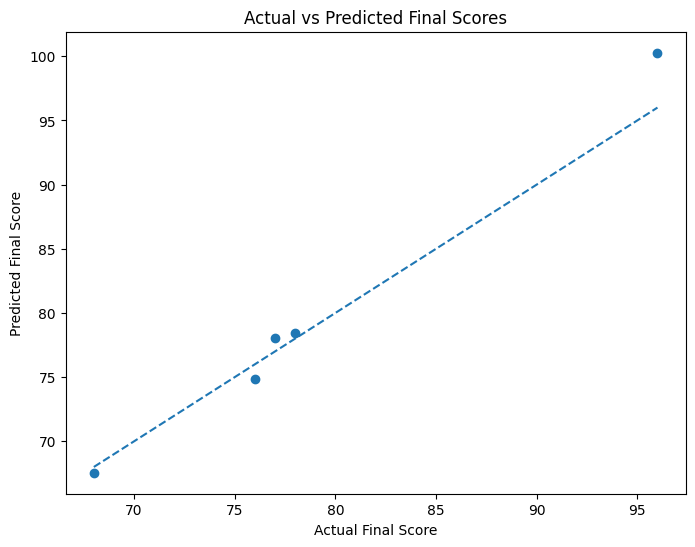

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")
plt.title("Actual vs Predicted Final Scores")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [19]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

,Feature,Coefficient
0,attendance_pct,0.514332
1,study_hours_per_week,1.310683
2,previous_score,0.127620


In [20]:
print("Intercept:", model.intercept_)

Intercept: 9.808515713784388


## Limitations

The baseline model has several limitations:

1. The dataset contains only a small number of observations, which may limit the reliability of the model.
2. Linear Regression assumes a linear relationship between the input features and Final Score.
3. Only a limited number of features were used for prediction.
4. The model may not generalize well to students with characteristics that are not represented in the dataset.
5. More data and additional relevant features could improve the model's predictive performance.

Therefore, this model should be considered a baseline model rather than a final production-ready prediction system.

## Conclusion

A Linear Regression model was successfully trained to predict student Final Scores using Study Hours, Attendance, and Previous Score.

The model was evaluated using MAE, MSE, RMSE, and R² Score. The evaluation results provide a baseline understanding of how accurately the selected features can predict student performance.

Future improvements could include collecting more data, adding additional relevant features, testing other regression algorithms, and using cross-validation for more reliable evaluation.